In [1]:
import os
import sys
import math
import numpy as np
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

## Perturbation theory and truncated diagonalization comparison

In [2]:
def get_plot_data(label):
    with h5py.File(f"/data/iiyama/2dz2/square_lattice_ising_8x4_{label}_mu0.5-3.5.h5", "r") as f:
        mus = f['mus'][()]
        eigvals = f['eigvals'][()]

    with h5py.File(f'/data/iiyama/2dz2/square_lattice_ising_td_8x4_{label}_mu0.5-3.5.h5', 'r') as source:
        order = source['order'][()]
        tqd_energy = source['energies'][()]

    with h5py.File(f'/data/iiyama/2dz2/square_lattice_ising_pt_8x4_{label}.h5', 'r') as source:
        pt_ecoeffs = source['pt_ecoeffs'][()]

    pt_energy = np.sum(pt_ecoeffs * np.power(mus[:, None], np.arange(0, order + 1, 2)), axis=1)

    return mus, eigvals, pt_energy, tqd_energy

mus, exact_vac, pt_vac, td_vac = get_plot_data('vac')
mus, exact_chg, pt_chg, td_chg = get_plot_data('ch0,2-8,2')

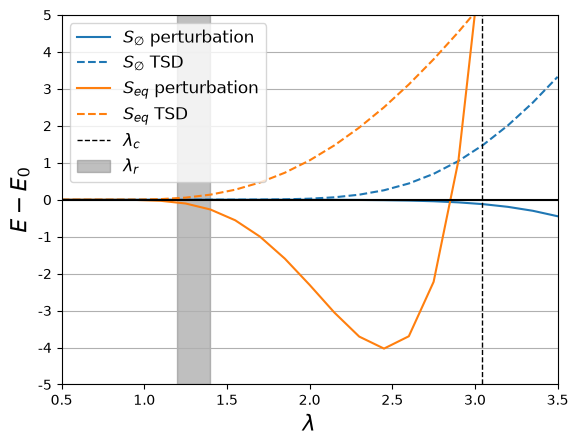

In [3]:
line, = plt.plot(mus, pt_vac - exact_vac, label=r'$S_{\emptyset}$ perturbation')
plt.plot(mus, td_vac - exact_vac, color=line.get_color(), linestyle='--', label=r'$S_{\emptyset}$ TSD')
line, = plt.plot(mus, pt_chg - exact_chg, label=r'$S_{eq}$ perturbation')
plt.plot(mus, td_chg - exact_chg, color=line.get_color(), linestyle='--', label=r'$S_{eq}$ TSD')
plt.axhline(0., color='k')
plt.xlim(0.5, 3.5)
plt.ylim(-5., 5.)
plt.yticks(np.linspace(-5., 5., 11), [f'{y}' for y in range(-5, 6)])
plt.axvline(3.044, linestyle='--', color='k', linewidth=1., label=r'$\lambda_c$')
plt.axvspan(1.2, 1.4, color='gray', alpha=0.5, label=r'$\lambda_r$')
plt.grid(axis='y')
plt.xlabel(r'$\lambda$', fontsize=16)
plt.ylabel('$E - E_0$', fontsize=16)
plt.legend(fontsize=12)
plt.savefig('/data/iiyama/2dz2/plots/pt_tsd_comp_square32.pdf')

## Configuration probabilities

/data/iiyama/venv/qii-miyabi-kawasaki/lib/python3.12/site-packages/matplotlib/axes/_axes.py:9261: RuntimeWarning: invalid value encountered in divide
  vals = 0.5 * width * vals / vals.max()


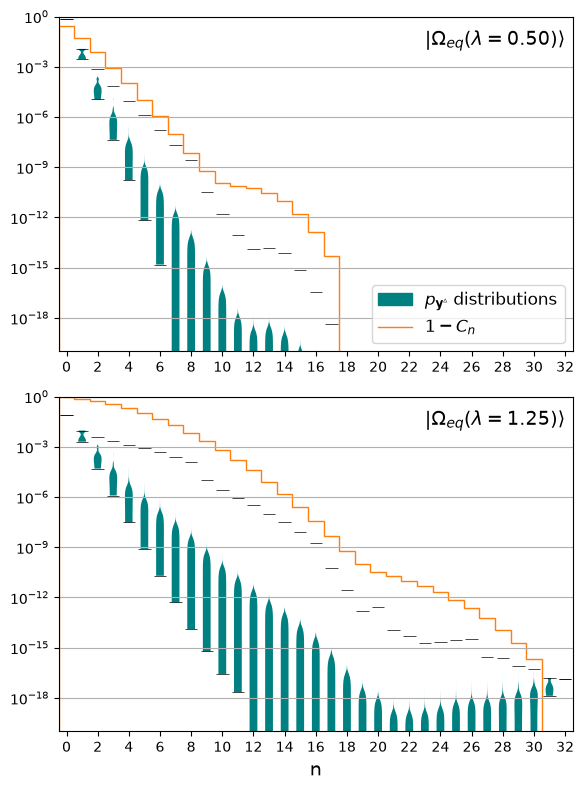

In [5]:
nplaq = 32
fig, axs = plt.subplots(2, 1, sharex=False, figsize=(6, 8))

for imu, ax in zip([0, 5], axs):
    with h5py.File("/data/iiyama/2dz2/square_lattice_ising_8x4_ch0,2-8,2_mu0.5-3.5.h5", "r") as f:
    #with h5py.File("/data/iiyama/2dz2/square_lattice_ising_8x4_vac_mu0.5-3.5.h5", "r") as f:
        mu, eigval, pkdes, kde_coords, ptots = (
            f[name][imu] for name in ("mus", "eigvals", "pkdes", "kde_coords", "ptots")
        )

    vpstats = []
    for weight in range(nplaq + 1):
        vpstats.append({
            'coords': kde_coords[weight],
            'vals': pkdes[weight],
            'mean': ptots[weight] / math.comb(nplaq, weight),
            'median': ptots[weight] / math.comb(nplaq, weight),
            'min': kde_coords[weight, 0],
            'max': kde_coords[weight, -1]
        })

    violin_parts = ax.violin(vpstats, positions=np.arange(nplaq + 1), facecolor='teal')
    # violin_parts['cbars'].set(color='k', linestyle=':', linewidth=0.2)
    violin_parts['cbars'].set(linewidth=0.)
    for ext in ['cmaxes', 'cmins']:
        for x, path in zip(np.arange(nplaq + 1), violin_parts[ext].get_paths()):
            path.vertices[:, 0] = x + np.array([-0.4, 0.4])
        violin_parts[ext].set(color='k', linewidth=0.5)
    steps = ax.stairs(1. - np.cumsum(ptots), np.linspace(-0.5, nplaq + 0.5, nplaq + 2), label=r'$1 - C_{n}$')
    ax.set_xticks(np.arange(0, nplaq + 1, 2), [f'{i}' for i in range(0, nplaq + 1, 2)])
    ax.set_yscale('log')
    ax.set_ylim(1.e-20, 1.)
    ax.set_xlim(-0.5, nplaq + 0.5)
    ax.grid(axis='y')
    ax.text(nplaq - 9, 0.02, fr'$|\Omega_{{eq}}(\lambda = {mu:.2f}) \rangle$', fontsize=14)

axs[1].set_xlabel('n', fontsize=14)
# axs[0].set_ylabel(r'$p_{\mathbf{y}}$', fontsize=14)
# axs[1].set_ylabel(r'$p_{\mathbf{y}}$', fontsize=14)

# legend_patches = []
patch = Patch(color=violin_parts['bodies'][0].get_facecolor(), label=r'$p_{\mathbf{y}^{\vartriangle}}$ distributions')

axs[0].legend(handles=[patch, steps], fontsize=12, loc='lower right') #, bbox_to_anchor=(0.98, 0.9))

fig.canvas.draw()
fig.tight_layout()
fig.savefig('/data/iiyama/2dz2/plots/sparsity_square32_charged.pdf')
